# Lab Assignment 13

**Prerequisite:** the class demo notebook *ICL_and_Instruction_Finetuning_Demo.ipynb*  
**Runtime:** Google Colab with a T4 GPU (about 10–15 minutes of GPU time per task)

Each task is a small, real NLP problem: you design the solution, run the experiments and explain what you found. Only data loading and evaluation functions are given, so that everyone's numbers are comparable.

## Rules
- Use only the models named in each task.
- You may reuse any code from the class demo. Cite any other source.
- Fix random seeds and report the settings you used.
- The two tasks are independent, so you can restart the runtime between them.

## Submission
Submit this notebook as `.ipynb` **with all outputs visible**.

## 0. Setup

In [18]:
!pip install -q transformers datasets accelerate sentence-transformers scikit-learn

In [19]:
import re, time, random, gc, sqlite3, warnings
from collections import Counter
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from IPython.display import display
from datasets import load_dataset
from transformers import (AutoTokenizer, AutoModelForCausalLM, DataCollatorForSeq2Seq,
                          Trainer, TrainingArguments)

warnings.filterwarnings("ignore")
pd.set_option("display.max_colwidth", 300)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)


def set_seed(seed=0):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


def clear_gpu():
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()


def load_causal_lm(name):
    """Load a decoder-only model in fp32 (numerically safe on a T4) and its tokenizer."""
    tok = AutoTokenizer.from_pretrained(name)
    if tok.pad_token is None:
        tok.pad_token = tok.eos_token
    model = AutoModelForCausalLM.from_pretrained(name).to(device).eval()
    return tok, model


@torch.no_grad()
def generate_batch(model, tok, prompts, max_new_tokens=64, batch_size=8, stop_strings=None, desc="generating"):
    """Greedy, batched generation. Returns only the new text for each prompt, cut at the first stop string."""
    kwargs = dict(stop_strings=stop_strings, tokenizer=tok) if stop_strings else {}
    old_side, tok.padding_side = tok.padding_side, "left"
    outputs = []
    for i in tqdm(range(0, len(prompts), batch_size), desc=desc, leave=False):
        enc = tok(prompts[i:i + batch_size], return_tensors="pt", padding=True).to(device)
        gen = model.generate(**enc, max_new_tokens=max_new_tokens, do_sample=False,
                             pad_token_id=tok.pad_token_id, **kwargs)
        for row in gen[:, enc["input_ids"].shape[1]:]:
            text = tok.decode(row, skip_special_tokens=True)
            for s in (stop_strings or []):
                text = text.split(s)[0]
            outputs.append(text.strip())
    tok.padding_side = old_side
    return outputs

Device: cuda


---
# Section A: In-Context Learning

## Task 1. A news-topic classifier with zero training (50 marks)

**Scenario.** A news website wants to tag articles as **World**, **Sports**, **Business** or **Sci/Tech**. It has only 200 labelled articles and no budget to train a model. Build the best classifier you can using **only in-context learning**, then decide whether it is actually a better choice than a simple classical model.

**Constraints**
- Model: `Qwen/Qwen2.5-0.5B` (base). No weight updates.
- Demonstrations may only come from `ag_pool`, with **at most 8 per prompt**.
- Every prediction must be one of the four classes. Report final numbers on `ag_test` using `report_classification`.

**What you must do**
1. **Baselines.** Evaluate zero-shot and 8 randomly chosen demonstrations.
2. **Retrieval-based demonstrations.** For each test article, choose the 8 most similar articles from `ag_pool` as demonstrations, using sentence embeddings from `sentence-transformers/all-MiniLM-L6-v2`. Compare with random selection.
3. **Classical baseline.** Train TF-IDF + logistic regression on the same 200 articles.
4. **Error analysis.** Show the confusion matrix of your best system and explain 3 of its mistakes.

**Analysis questions** (about 250 words in total)
- (a) Did retrieval-based demonstrations beat random ones? Why do you think similar examples help?
- (b) Which classes get confused most often, and why might that be?
- (c) Compare your best ICL system with logistic regression on accuracy **and** speed (seconds per article). Which would you deploy for this website, and why?



In [20]:
ag = load_dataset("fancyzhx/ag_news")
AG_LABELS = ["World", "Sports", "Business", "Sci/Tech"]

ag_test = ag["test"].shuffle(seed=0).select(range(200))
_train = ag["train"].shuffle(seed=1)
ag_pool = _train.select(range(200))          # the ONLY labelled data you may use
ag_dev = _train.select(range(200, 300))      # use for design decisions (prompt format, label words)

for name, ds in [("pool", ag_pool), ("dev", ag_dev), ("test", ag_test)]:
    counts = Counter(ds["label"])
    print(f"{name:5s}", {AG_LABELS[k]: counts[k] for k in range(4)})
print("\nExample:", ag_pool[0])

pool  {'World': 48, 'Sports': 53, 'Business': 49, 'Sci/Tech': 50}
dev   {'World': 23, 'Sports': 26, 'Business': 33, 'Sci/Tech': 18}
test  {'World': 49, 'Sports': 47, 'Business': 50, 'Sci/Tech': 54}

Example: {'text': "Brown feels fortunate to have a hand in series Thirty-two pitches. That's a couple innings for most pitchers -- or two lengthy Johnny Damon at-bats. It amounted to Kevin Brown's entire body of work against the Red Sox Sept. 26. It was not a pretty sight.", 'label': 1}


In [21]:
from sklearn.metrics import accuracy_score, f1_score, ConfusionMatrixDisplay

RESULTS_T1 = []   # append the dict returned by report_classification for every system


def report_classification(y_true, y_pred, method, sec_per_example=None, show_cm=False):
    """Fixed evaluation for Task 1. y_true / y_pred are lists of label ids (0-3)."""
    res = {"method": method,
           "accuracy": accuracy_score(y_true, y_pred),
           "macro_f1": f1_score(y_true, y_pred, average="macro"),
           "sec_per_example": sec_per_example}
    if show_cm:
        ConfusionMatrixDisplay.from_predictions(y_true, y_pred, labels=list(range(4)), display_labels=AG_LABELS,
                                                cmap="Blues", xticks_rotation=45)
        plt.title(method); plt.show()
    return res

### Task 1: Your solution
Add as many code and text cells as you need.

### Approach
- **Model:** `Qwen/Qwen2.5-0.5B` (base), no weight updates, fp32, greedy.
- **Guaranteeing valid labels:** instead of free generation, I read the next-token logits after `Topic:` and take the argmax over the four label words (`World`, `Sports`, `Business`, `Technology`). The prediction is therefore always one of the four classes.
- **Prompt format:** instruction + `Article: ...\nTopic: <label>` demonstrations. Articles are truncated to 60 words to keep 8-shot prompts short.
- **Seeds:** global seed = 0. Random demos for test example `i` use `random.Random(0 + i)`.
- **Demonstrations come only from `ag_pool`.** `ag_dev` is used only for design decisions.

In [22]:
SEED = 0
set_seed(SEED)
clear_gpu()

from sentence_transformers import SentenceTransformer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline

tok, model = load_causal_lm("Qwen/Qwen2.5-0.5B")

LABEL_WORDS = ["World", "Sports", "Business", "Technology"]   # index = AG label id
label_ids = [tok.encode(" " + w)[0] for w in LABEL_WORDS]     # first token of each label word
assert len(set(label_ids)) == 4, "label words must have distinct first tokens"
print(label_ids, [tok.decode(i) for i in label_ids])

pool_texts, pool_labels = ag_pool["text"], ag_pool["label"]
dev_texts,  dev_labels  = ag_dev["text"],  ag_dev["label"]
test_texts, test_labels = ag_test["text"], ag_test["label"]

INSTR = "Classify each news article into one of four topics: World, Sports, Business, Technology.\n\n"

def trunc(t, n=60):
    return " ".join(t.split()[:n])

def fmt(text, label=None):
    s = f"Article: {trunc(text)}\nTopic:"
    return s + (f" {LABEL_WORDS[label]}\n\n" if label is not None else "")

def build_prompt(text, demos):
    """demos: list of (text, label) pairs from ag_pool."""
    return INSTR + "".join(fmt(t, l) for t, l in demos) + fmt(text)

@torch.no_grad()
def classify(prompts, batch_size=4, desc="classifying"):
    """Argmax over the 4 label-word logits at the last position -> always a valid class."""
    old, tok.padding_side = tok.padding_side, "left"
    preds = []
    for i in tqdm(range(0, len(prompts), batch_size), desc=desc, leave=False):
        enc = tok(prompts[i:i + batch_size], return_tensors="pt", padding=True).to(device)
        h = model.model(**enc).last_hidden_state[:, -1]      # avoid full-vocab logits for every position
        logits = model.lm_head(h)
        preds += logits[:, label_ids].argmax(-1).tolist()
    tok.padding_side = old
    return preds

print(build_prompt(test_texts[0], [(pool_texts[0], pool_labels[0])])[:700])

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

[4337, 13180, 8025, 11791] [' World', ' Sports', ' Business', ' Technology']
Classify each news article into one of four topics: World, Sports, Business, Technology.

Article: Brown feels fortunate to have a hand in series Thirty-two pitches. That's a couple innings for most pitchers -- or two lengthy Johnny Damon at-bats. It amounted to Kevin Brown's entire body of work against the Red Sox Sept. 26. It was not a pretty sight.
Topic: Sports

Article: McTeer: Lonesome Dove to be an Aggie NEW YORK (CNN/Money) - A New Economy champion, a lover of the Texas picker poets who write lovesick country songs...and, oh, by the way, a member of the Federal Reserve system for 36 years.
Topic:


In [23]:
embedder = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2", device=device)
pool_emb = embedder.encode(pool_texts, normalize_embeddings=True, convert_to_numpy=True)

def zero_shot_demos(texts):
    return [[] for _ in texts]

def random_demos(texts, k=8):
    out = []
    for i, _ in enumerate(texts):
        idx = random.Random(SEED + i).sample(range(len(pool_texts)), k)
        out.append([(pool_texts[j], pool_labels[j]) for j in idx])
    return out

def retrieval_demos(texts, k=8):
    q = embedder.encode(texts, normalize_embeddings=True, convert_to_numpy=True)
    sims = q @ pool_emb.T
    out = []
    for row in sims:
        top = np.argsort(-row)[:k][::-1]          # most similar example LAST (closest to the query)
        out.append([(pool_texts[j], pool_labels[j]) for j in top])
    return out

def run_icl(name, demo_builder, texts, labels, show_cm=False):
    t0 = time.time()                               # timing includes retrieval/embedding cost
    demos = demo_builder(texts)
    prompts = [build_prompt(t, d) for t, d in zip(texts, demos)]
    preds = classify(prompts, desc=name)
    sec = (time.time() - t0) / len(texts)
    return preds, report_classification(labels, preds, name, sec, show_cm)

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

In [24]:
dev_rows = []
for name, builder in [("zero-shot", zero_shot_demos), ("random-8", random_demos), ("retrieval-8", retrieval_demos)]:
    _, r = run_icl(name, builder, dev_texts, dev_labels)
    dev_rows.append(r)
display(pd.DataFrame(dev_rows).round(3))

zero-shot:   0%|          | 0/25 [00:00<?, ?it/s]

random-8:   0%|          | 0/25 [00:00<?, ?it/s]

retrieval-8:   0%|          | 0/25 [00:00<?, ?it/s]

,method,accuracy,macro_f1,sec_per_example
0,zero-shot,0.71,0.591,0.057
1,random-8,0.76,0.736,0.256
2,retrieval-8,0.85,0.837,0.293


In [25]:
set_seed(SEED)
preds_zero, r = run_icl("ICL zero-shot", zero_shot_demos, test_texts, test_labels);   RESULTS_T1.append(r)
preds_rand, r = run_icl("ICL random-8", random_demos, test_texts, test_labels);       RESULTS_T1.append(r)
preds_retr, r = run_icl("ICL retrieval-8 (MiniLM)", retrieval_demos, test_texts, test_labels); RESULTS_T1.append(r)
display(pd.DataFrame(RESULTS_T1).round(3))

ICL zero-shot:   0%|          | 0/50 [00:00<?, ?it/s]

ICL random-8:   0%|          | 0/50 [00:00<?, ?it/s]

ICL retrieval-8 (MiniLM):   0%|          | 0/50 [00:00<?, ?it/s]

,method,accuracy,macro_f1,sec_per_example
0,ICL zero-shot,0.605,0.540,0.055
1,ICL random-8,0.770,0.771,0.261
2,ICL retrieval-8 (MiniLM),0.865,0.868,0.267


In [26]:
# choose C on the dev set (not on test)
best_C, best_acc = None, -1
for C in [0.1, 1, 10, 100]:
    p = make_pipeline(TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True),
                      LogisticRegression(C=C, max_iter=2000, random_state=SEED))
    p.fit(pool_texts, pool_labels)
    acc = accuracy_score(dev_labels, p.predict(dev_texts))
    print(f"C={C:<6} dev acc={acc:.3f}")
    if acc > best_acc: best_C, best_acc = C, acc

clf = make_pipeline(TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True),
                    LogisticRegression(C=best_C, max_iter=2000, random_state=SEED))
t0 = time.time(); clf.fit(pool_texts, pool_labels); train_time = time.time() - t0

t0 = time.time(); preds_lr = clf.predict(test_texts).tolist()
sec_lr = (time.time() - t0) / len(test_texts)
RESULTS_T1.append(report_classification(test_labels, preds_lr, f"TF-IDF + LogReg (C={best_C})", sec_lr))
print(f"LogReg training time: {train_time:.2f}s")

C=0.1    dev acc=0.380
C=1      dev acc=0.720
C=10     dev acc=0.720
C=100    dev acc=0.720
LogReg training time: 0.85s


,method,accuracy,macro_f1,sec_per_example
0,ICL zero-shot,0.605,0.5399,0.0545
1,ICL random-8,0.770,0.7714,0.2615
2,ICL retrieval-8 (MiniLM),0.865,0.8681,0.2666
3,TF-IDF + LogReg (C=1),0.720,0.7203,0.0005


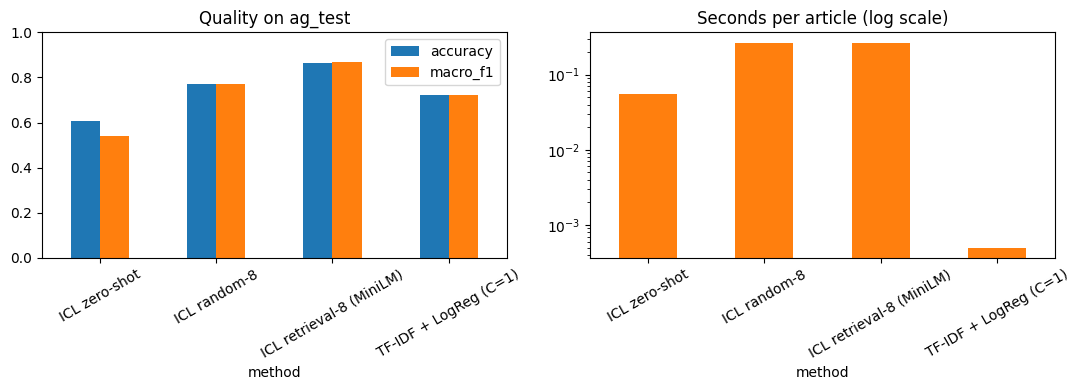

In [27]:
df1 = pd.DataFrame(RESULTS_T1).round(4)
display(df1)

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
df1.set_index("method")[["accuracy", "macro_f1"]].plot.bar(ax=ax[0], rot=30)
ax[0].set_ylim(0, 1); ax[0].set_title("Quality on ag_test")
df1.set_index("method")["sec_per_example"].plot.bar(ax=ax[1], rot=30, logy=True, color="tab:orange")
ax[1].set_title("Seconds per article (log scale)")
plt.tight_layout(); plt.show()

Best ICL system: ICL retrieval-8 (MiniLM)


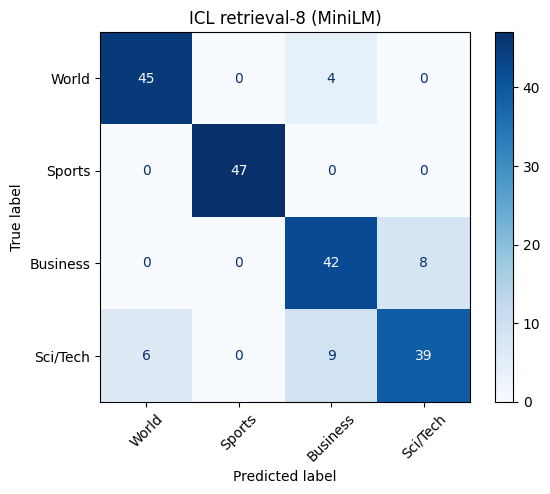

27 mistakes out of 200
Most common (true -> predicted) confusions:
  Sci/Tech  -> Business  : 9
  Business  -> Sci/Tech  : 8
  Sci/Tech  -> World     : 6
  World     -> Business  : 4

--------------------------------------------------------------------------------
[7] TRUE: Sci/Tech | PRED: Business
Intel drops prices on computer chips SAN FRANCISCO - Intel Corp. has cut prices on its computer chips by as much as 35 percent, though analysts on Monday said the cuts were probably unrelated to swelling inventories of the world #39;s largest chip maker.

--------------------------------------------------------------------------------
[12] TRUE: Sci/Tech | PRED: World
Study: Wrecks Jump 3 Days After Terrorism Fatal traffic accidents increase sharply in Israel on the third day after a terrorist attack, and researchers are searching for an explanation why.

--------------------------------------------------------------------------------
[20] TRUE: Sci/Tech | PRED: Business
Cisco to acquire P-

In [28]:
icl_results = {"ICL zero-shot": preds_zero, "ICL random-8": preds_rand, "ICL retrieval-8 (MiniLM)": preds_retr}
best_name = max([r for r in RESULTS_T1 if r["method"] in icl_results], key=lambda r: r["accuracy"])["method"]
best_preds = icl_results[best_name]
print("Best ICL system:", best_name)

_ = report_classification(test_labels, best_preds, best_name, show_cm=True)

wrong = [i for i, (p, y) in enumerate(zip(best_preds, test_labels)) if p != y]
print(f"{len(wrong)} mistakes out of {len(test_labels)}")
print("Most common (true -> predicted) confusions:")
for (t, p), c in Counter((AG_LABELS[test_labels[i]], AG_LABELS[best_preds[i]]) for i in wrong).most_common(5):
    print(f"  {t:9s} -> {p:9s} : {c}")

for i in wrong[:3]:      # or pick 3 you find most interesting
    print("\n" + "-" * 80)
    print(f"[{i}] TRUE: {AG_LABELS[test_labels[i]]} | PRED: {AG_LABELS[best_preds[i]]}")
    print(test_texts[i])

### Task 1: Results and analysis ✍️

_Results table, plots, and answers to the analysis questions go here._

### Results (all on `ag_test`, 200 articles)

| Method | Accuracy | Macro-F1 | Sec / article |
|---|---|---|---|
| ICL zero-shot | 0.605 | 0.540 | 0.055 |
| ICL random-8 | 0.770 | 0.771 | 0.262 |
| **ICL retrieval-8 (MiniLM)** | **0.865** | **0.868** | 0.267 |
| TF-IDF + LogReg (C=1) | 0.720 | 0.720 | 0.0005 |

Design choices were made on `ag_dev` only (zero-shot 0.71, random-8 0.76, retrieval-8 0.85 accuracy there; LogReg's `C` was also picked on dev). **Seeds:** global seed 0; random demos for article `i` use `Random(0+i)`; greedy decoding; LogReg `random_state=0`. LogReg trained in 0.85 s.

### Three mistakes explained (best system: retrieval-8, 27 errors out of 200)
1. **[7] True Sci/Tech → Pred Business.** "Intel drops prices on computer chips... analysts said the cuts were unrelated to swelling inventories." The story is about a tech company, but its vocabulary (price cuts, inventories, analysts, percent) is pure business reporting. The label comes from the news section it was filed under, not from the words.
2. **[12] True Sci/Tech → Pred World.** "Study: Wrecks Jump 3 Days After Terrorism... in Israel." This is a science-news item (a research study on traffic accidents), but "Israel" and "terrorism" are strong geopolitical cues, so the model chose World.
3. **[20] True Sci/Tech → Pred Business.** "Cisco to acquire P-Cube for $200M in stock and cash." An acquisition story about a networking company. Words like "acquire", "$200 million", "stock" push it to Business, and nearby Business demonstrations probably reinforced that.

### Analysis
**(a) Retrieval vs random.** Yes. Retrieval-8 reached 86.5% accuracy against 77.0% for random-8 and 60.5% for zero-shot, a gain of 9.5 points over random. Similar articles share entities, vocabulary and sub-topic with the query, so their labels work as near-neighbours the model can copy. This suits a 0.5B base model, which follows examples better than abstract instructions. Random demos can be unbalanced across classes or unrelated to the query. Putting the most similar example last also helps through recency bias.

**(b) Confusions.** Business and Sci/Tech are confused most: Sci/Tech→Business 9 and Business→Sci/Tech 8, which is 17 of the 27 errors. Next come Sci/Tech→World (6) and World→Business (4). The topics overlap, because tech-company stories (chips, acquisitions, earnings) are also business news. AG News labels come from the source section, not strict content. Sports is almost never confused because its vocabulary is distinctive.

**(c) ICL vs logistic regression.** ICL retrieval-8 scored 86.5% at 0.267 s/article. LogReg scored 72.0% at 0.0005 s/article, about 500× faster, with no GPU. With only 200 labels, the 14.5-point accuracy gap is larger than the ±5–6 point sampling error on 200 test articles. **I would deploy ICL with retrieval.** At 0.27 s/article, 10,000 articles take about 45 minutes on one T4, which is acceptable for tagging news. LogReg would be the choice if volume were very large or no GPU were available, and it would improve as more labels arrive.

---
# Section B: Instruction Fine-Tuning

## Task 2. English → SQL: prompt a ready-made model or fine-tune your own? (50 marks)

**Scenario.** A company wants its analysts to query databases in plain English. Given a table schema (a `CREATE TABLE` statement) and a question, a model must write the SQL query. Should the company **prompt** an existing instruction-tuned model, or **fine-tune** a small model on examples? Build both and recommend one.

**Data:** each example has a `question`, a `context` (the schema) and an `answer` (the gold SQL).

**Constraints**
- Prompting system: `Qwen/Qwen2.5-0.5B-Instruct` (use its chat template).
- Fine-tuned system: `openai-community/gpt2` (124M), with the loss computed on the SQL tokens only.
- Training and demonstration data come only from `sql_train_pool`. Evaluate every system on `sql_test` with `evaluate_sql`.

**What you must do**
1. **Prompting baseline.** Prompt Qwen2.5-0.5B-Instruct with 3 examples from the pool. The model may add explanations or code fences, so extract just the SQL from its output.
2. **Fine-tuning.** Design an input format for (schema, question) → SQL and fine-tune GPT-2 twice, on **500** and on **2,000** examples, with the same hyperparameters.
3. **Error analysis.** Look at 10 mistakes of your best system and label each one: wrong column, wrong condition or aggregate, wrong value, invalid SQL, or correct but written differently.

**Analysis questions** (about 250 words in total)
- (a) How did fine-tuned GPT-2 compare with prompting a model four times its size? How much did going from 500 to 2,000 examples help?
- (b) How many of your "mistakes" were actually correct queries written differently? Why does exact match underestimate performance?
- (c) Write a short recommendation to the company: prompting or fine-tuning? Consider accuracy, the labelled data needed, cost, and what happens when new tables are added.

**Marking:** prompting baseline 12 · fine-tuning (both sizes) 18 · error analysis 8 · discussion 12

In [29]:
sql_ds = load_dataset("b-mc2/sql-create-context", split="train").shuffle(seed=0)
sql_test = sql_ds.select(range(200))
sql_train_pool = sql_ds.select(range(200, 5200))   # training, validation and demonstration data

ex = sql_test[0]
print("SCHEMA  :", ex["context"]); print("QUESTION:", ex["question"]); print("GOLD SQL:", ex["answer"])

SCHEMA  : CREATE TABLE table_24463470_1 (unlock_order INTEGER, circuit VARCHAR)
QUESTION: What is the lowest unlock order for the athens circuit?
GOLD SQL: SELECT MIN(unlock_order) FROM table_24463470_1 WHERE circuit = "Athens"


In [30]:
def normalize_sql(q):
    """Lenient normalisation for exact match: case, whitespace, quote style, trailing semicolon."""
    q = q.strip().rstrip(";").replace('"', "'")
    q = re.sub(r"\s+", " ", q)
    q = re.sub(r"\s*([(),=<>])\s*", r"\1", q)
    return q.lower().strip()


def executes(sql, context):
    """True if the query runs without error on an empty database built from the schema."""
    con = sqlite3.connect(":memory:")
    try:
        con.executescript(context)
        con.execute(sql).fetchall()
        return True
    except Exception:
        return False
    finally:
        con.close()


def evaluate_sql(preds, dataset, system):
    """Fixed evaluation for Task 2. preds: list of SQL strings aligned with dataset."""
    golds, contexts = dataset["answer"], dataset["context"]
    return {"system": system,
            "exact_match": float(np.mean([normalize_sql(p) == normalize_sql(g) for p, g in zip(preds, golds)])),
            "executable": float(np.mean([executes(p, c) for p, c in zip(preds, contexts)]))}


RESULTS_T2 = []   # append the dict returned by evaluate_sql for every system
print("Reference (gold queries):", evaluate_sql(sql_test["answer"], sql_test, "gold"))

Reference (gold queries): {'system': 'gold', 'exact_match': 1.0, 'executable': 0.975}


### Task 2: Your solution
Add as many code and text cells as you need.

### Approach
- **Prompting:** `Qwen2.5-0.5B-Instruct` with its chat template, a system message and 3 demonstrations from `sql_train_pool` (fixed random sample, seed 0) as user/assistant turns. Output is cleaned with `extract_sql` (strips code fences/explanations, keeps the first statement).
- **Fine-tuning:** GPT-2 (124M) with input format
  `### Schema:\n{context}\n### Question:\n{question}\n### SQL:\n{answer}<eos>`; **loss only on the SQL tokens** (prompt labels = -100).
- **Same hyperparameters for 500 and 2,000 examples:** lr 1e-4, 3 epochs, batch 8, linear decay, warmup 5%, weight decay 0.01, seed 0, fp32. The 2,000-example run therefore takes 4× more update steps.
- Training examples are nested subsets (first 500 ⊂ first 2,000) of the pool, restricted to ≤256 tokens. Validation (200 examples) and demonstrations come from other parts of the pool, never from `sql_test`.

In [31]:
clear_gpu(); set_seed(0)
try: del model, embedder          # free Task 1 objects if the runtime wasn't restarted
except NameError: pass
clear_gpu()

tok_q, model_q = load_causal_lm("Qwen/Qwen2.5-0.5B-Instruct")

demo_idx = random.Random(0).sample(range(4500, 5000), 3)     # pool rows reserved for demonstrations
demos = [sql_train_pool[i] for i in demo_idx]

SYSTEM = ("You are a text-to-SQL assistant. Given a table schema and a question, "
          "reply with a single SQL query and nothing else.")

def user_msg(ex):
    return f"Schema:\n{ex['context']}\n\nQuestion: {ex['question']}"

def build_chat(ex):
    msgs = [{"role": "system", "content": SYSTEM}]
    for d in demos:
        msgs += [{"role": "user", "content": user_msg(d)}, {"role": "assistant", "content": d["answer"]}]
    msgs.append({"role": "user", "content": user_msg(ex)})
    return tok_q.apply_chat_template(msgs, tokenize=False, add_generation_prompt=True)

def extract_sql(text):
    m = re.search(r"```(?:sql)?\s*(.*?)```", text, re.S | re.I)      # closed code fence
    text = m.group(1) if m else re.sub(r"^\s*```(?:sql)?", "", text)  # or an unclosed one
    m = re.search(r"\b(select|with)\b.*", text, re.S | re.I)         # drop any leading chatter
    if m: text = m.group(0)
    text = text.split(";")[0].split("\n\n")[0]                       # first statement only
    return " ".join(text.split())

prompts_q = [build_chat(e) for e in sql_test]
raw_q = generate_batch(model_q, tok_q, prompts_q, max_new_tokens=120, batch_size=8, desc="Qwen-Instruct")
preds_qwen = [extract_sql(o) for o in raw_q]

for i in range(3):
    print("RAW :", raw_q[i][:200].replace("\n", " ⏎ "))
    print("SQL :", preds_qwen[i]); print("GOLD:", sql_test[i]["answer"]); print()

r = evaluate_sql(preds_qwen, sql_test, "Qwen2.5-0.5B-Instruct, 3-shot"); RESULTS_T2.append(r); print(r)
del model_q; clear_gpu()

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

Qwen-Instruct:   0%|          | 0/25 [00:00<?, ?it/s]

RAW : SELECT min(unlock_order) FROM table_24463470_1 WHERE circuit = "athens"
SQL : SELECT min(unlock_order) FROM table_24463470_1 WHERE circuit = "athens"
GOLD: SELECT MIN(unlock_order) FROM table_24463470_1 WHERE circuit = "Athens"

RAW : SELECT pick__number FROM table_name_99 WHERE overall < 136 AND position = "Defensive Back" ORDER BY pick__number DESC LIMIT 1
SQL : SELECT pick__number FROM table_name_99 WHERE overall < 136 AND position = "Defensive Back" ORDER BY pick__number DESC LIMIT 1
GOLD: SELECT MAX(pick__number) FROM table_name_99 WHERE overall < 136 AND position = "defensive back"

RAW : SELECT engine FROM table_name_74 WHERE year > 1956
SQL : SELECT engine FROM table_name_74 WHERE year > 1956
GOLD: SELECT engine FROM table_name_74 WHERE year > 1956

{'system': 'Qwen2.5-0.5B-Instruct, 3-shot', 'exact_match': 0.445, 'executable': 0.905}


In [32]:
MAX_LEN = 256
tok_g = AutoTokenizer.from_pretrained("openai-community/gpt2")
tok_g.pad_token = tok_g.eos_token

def make_prompt(ex):
    return f"### Schema:\n{ex['context']}\n### Question:\n{ex['question']}\n### SQL:\n"

def encode(ex):
    p = tok_g(make_prompt(ex))["input_ids"]
    a = tok_g(ex["answer"])["input_ids"] + [tok_g.eos_token_id]
    ids = p + a
    return {"input_ids": ids, "attention_mask": [1] * len(ids),
            "labels": [-100] * len(p) + a}                    # loss only on SQL (+ EOS)

def prep(ds):
    cols = ds.column_names
    return ds.map(encode, remove_columns=cols).filter(lambda e: len(e["input_ids"]) <= MAX_LEN)

train_all = prep(sql_train_pool.select(range(0, 4000)))
train_sets = {500: train_all.select(range(500)), 2000: train_all.select(range(2000))}
val_enc = prep(sql_train_pool.select(range(4000, 4200)))
print({k: len(v) for k, v in train_sets.items()}, "val:", len(val_enc))

# sanity check: only SQL tokens contribute to the loss
e = train_sets[500][0]
print("Supervised part:", tok_g.decode([t for t, l in zip(e["input_ids"], e["labels"]) if l != -100]))

{500: 500, 2000: 2000} val: 200
Supervised part: SELECT builder FROM table_name_6 WHERE tc & stl_no__1883_84_ > 54 AND date_ordered = "november 1881"<|endoftext|>


In [34]:
import math

EPOCHS, BATCH, LR = 3, 8, 1e-4

def finetune(n):
    set_seed(0)
    model = AutoModelForCausalLM.from_pretrained("openai-community/gpt2").float().to(device)

    steps_per_epoch = math.ceil(len(train_sets[n]) / BATCH)
    total_steps = steps_per_epoch * EPOCHS
    warmup = int(0.05 * total_steps)                      # 5% warmup, computed manually (works in all versions)
    print(f"[{n} examples] {steps_per_epoch} steps/epoch, {total_steps} total, {warmup} warmup")

    args = TrainingArguments(
        output_dir=f"gpt2_sql_{n}",
        per_device_train_batch_size=BATCH, per_device_eval_batch_size=16,
        num_train_epochs=EPOCHS, learning_rate=LR, lr_scheduler_type="linear",
        warmup_steps=warmup, weight_decay=0.01,
        logging_steps=50, save_strategy="no", report_to="none",
        seed=0, fp16=False, bf16=False)
    trainer = Trainer(model=model, args=args, train_dataset=train_sets[n], eval_dataset=val_enc,
                      data_collator=DataCollatorForSeq2Seq(tok_g, padding=True, label_pad_token_id=-100))
    trainer.train()
    val_loss = trainer.evaluate()["eval_loss"]
    print(f"[{n} examples] validation loss = {val_loss:.4f}")
    return trainer.model.eval(), val_loss

def predict_gpt2(model, data):
    outs = generate_batch(model, tok_g, [make_prompt(e) for e in data],
                          max_new_tokens=96, batch_size=16, desc="GPT-2")
    return [o.split("\n")[0].strip() for o in outs]

preds_gpt2 = {}
for n in [500, 2000]:
    m, vl = finetune(n)
    preds_gpt2[n] = predict_gpt2(m, sql_test)
    r = evaluate_sql(preds_gpt2[n], sql_test, f"GPT-2 fine-tuned ({n} ex)")
    r["val_loss"] = vl
    RESULTS_T2.append(r); print(r)
    for j in range(2):
        print("  PRED:", preds_gpt2[n][j]); print("  GOLD:", sql_test[j]["answer"])
    del m; clear_gpu()

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

[500 examples] 63 steps/epoch, 189 total, 9 warmup


[transformers] `loss_type=None` was set in the config but it is unrecognized. Using the default loss: `ForCausalLMLoss`.


Step,Training Loss
50,0.766006
100,0.311949
150,0.212187


Training Loss,Validation Loss,Step
0.212187,0.315382,189


[500 examples] validation loss = 0.3154


... (5 outputs left out)

Training Loss,Validation Loss,Step
0.102010,0.209683,750


[2000 examples] validation loss = 0.2097


GPT-2:   0%|          | 0/13 [00:00<?, ?it/s]

{'system': 'GPT-2 fine-tuned (2000 ex)', 'exact_match': 0.565, 'executable': 0.945, 'val_loss': 0.20968276262283325}
  PRED: SELECT MIN(unlock_order) FROM table_24463470_1 WHERE circuit = "ATLAS"
  GOLD: SELECT MIN(unlock_order) FROM table_24463470_1 WHERE circuit = "Athens"
  PRED: SELECT MAX(pick__number) FROM table_name_99 WHERE overall = "defensive back" AND position = "defensive back" AND pick__number < 136
  GOLD: SELECT MAX(pick__number) FROM table_name_99 WHERE overall < 136 AND position = "defensive back"


,system,exact_match,executable,val_loss
0,"Qwen2.5-0.5B-Instruct, 3-shot",0.445,0.905,NaN
1,GPT-2 fine-tuned (500 ex),0.465,0.895,0.3154
2,GPT-2 fine-tuned (2000 ex),0.565,0.945,0.2097


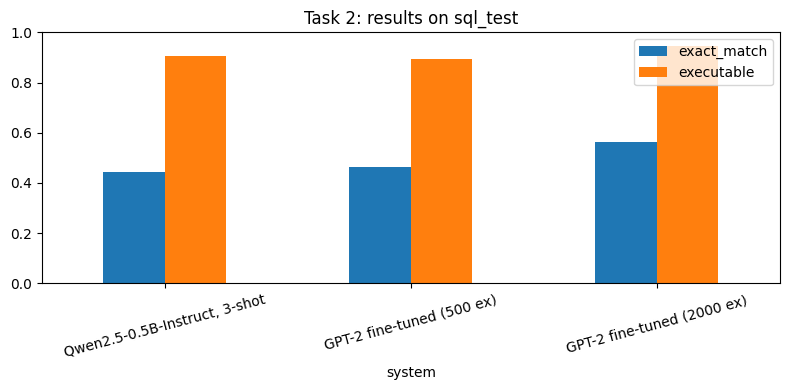

In [35]:
df2 = pd.DataFrame(RESULTS_T2).round(4)
display(df2)
df2.set_index("system")[["exact_match", "executable"]].plot.bar(rot=15, figsize=(8, 4))
plt.ylim(0, 1); plt.title("Task 2: results on sql_test"); plt.tight_layout(); plt.show()

In [36]:
all_preds = {"Qwen2.5-0.5B-Instruct, 3-shot": preds_qwen,
             "GPT-2 fine-tuned (500 ex)": preds_gpt2[500],
             "GPT-2 fine-tuned (2000 ex)": preds_gpt2[2000]}
best_sys = max(RESULTS_T2, key=lambda r: r["exact_match"] if r["system"] in all_preds else -1)["system"]
best_p = all_preds[best_sys]
print("Best system:", best_sys)

golds, ctxs, qs = sql_test["answer"], sql_test["context"], sql_test["question"]
tokset = lambda s: sorted(re.findall(r"[\w.]+|[^\s\w]", normalize_sql(s)))
mistakes = [i for i in range(len(golds)) if normalize_sql(best_p[i]) != normalize_sql(golds[i])]
reordered = [i for i in mistakes if tokset(best_p[i]) == tokset(golds[i])]   # same tokens, different order
print(f"{len(mistakes)} mistakes; {len(reordered)} of them have exactly the same tokens as gold (likely just reordered/rewritten)")

rows = [{"id": i, "question": qs[i], "gold": golds[i], "pred": best_p[i],
         "executes": executes(best_p[i], ctxs[i]), "same_tokens_as_gold": i in reordered}
        for i in mistakes[:10]]
display(pd.DataFrame(rows))

Best system: GPT-2 fine-tuned (2000 ex)
87 mistakes; 1 of them have exactly the same tokens as gold (likely just reordered/rewritten)


,id,question,gold,pred,executes,same_tokens_as_gold
0,0,What is the lowest unlock order for the athens circuit?,"SELECT MIN(unlock_order) FROM table_24463470_1 WHERE circuit = ""Athens""","SELECT MIN(unlock_order) FROM table_24463470_1 WHERE circuit = ""ATLAS""",True,False
1,1,What is the highest pick number of a defensive back with less than 136 overall points?,"SELECT MAX(pick__number) FROM table_name_99 WHERE overall < 136 AND position = ""defensive back""","SELECT MAX(pick__number) FROM table_name_99 WHERE overall = ""defensive back"" AND position = ""defensive back"" AND pick__number < 136",True,False
2,4,"What is the Netflix number having a segment D, of NED can corn?","SELECT netflix FROM table_name_2 WHERE segment_d = ""ned can corn""","SELECT COUNT(netflix) FROM table_name_2 WHERE segment_d = ""ned can corn""",True,False
3,8,Which country is Lemd the ICAO of?,"SELECT country FROM table_name_34 WHERE icao = ""lemd""","SELECT country FROM table_name_34 WHERE icao = ""lemd the icao""",True,False
4,11,What is the highest result for Jankovic at Indian Wells and round of SF?,"SELECT MAX(jankovic) FROM table_name_68 WHERE round = ""sf"" AND tournament = ""indian wells""","SELECT MAX(jankovic) FROM table_name_68 WHERE round = ""italian wells"" AND tournament = ""sf""",True,False
5,12,On what date were more than 5 built with 4-4-2 wheels?,"SELECT date FROM table_name_38 WHERE wheels = ""4-4-2"" AND no_built > 5",SELECT date FROM table_name_38 WHERE wheels > 5 AND no_built = 4 - 4 - 2,True,False
6,13,What was the attendance at the Meadowlands against the New England Patriots?,"SELECT attendance FROM table_name_63 WHERE game_site = ""the meadowlands"" AND opponent = ""new england patriots""","SELECT attendance FROM table_name_63 WHERE game_site = ""marshlands"" AND opponent = ""new England Patriots""",True,False
7,15,How many deductions have 56.5 as tosses/pyramids?,"SELECT deductions FROM table_22014431_3 WHERE tosses_pyramids = ""56.5""","SELECT COUNT(deductions) FROM table_22014431_3 WHERE tosses_pyramids = ""56.5""",True,False
8,20,Who was the Rookie of the Year for the Season in 2000?,SELECT rookie_of_the_year FROM table_name_72 WHERE season = 2000,"SELECT rookie_of_the_year FROM table_name_72 WHERE season = ""2000""",True,False
9,21,How many different shareholders have 2.39 % of capital?,"SELECT COUNT(shareholder_name) FROM table_206359_1 WHERE _percentage_of_capital = ""2.39""","SELECT COUNT(shareholder_name) FROM table_206359_1 WHERE _percentage_of_capital = ""2.39%""",True,False


In [38]:
CATS = ["wrong column", "wrong condition/aggregate", "wrong value", "invalid SQL", "correct but written differently"]

LABELS = {   # keys are the example ids from the table in the previous cell
    0:  "wrong value",                       # "ATLAS" instead of "Athens"
    1:  "wrong condition/aggregate",         # filters overall = 'defensive back' and pick__number < 136
    4:  "wrong condition/aggregate",         # adds COUNT(...) where gold has none
    8:  "wrong value",                       # "lemd the icao" instead of "lemd"
    11: "wrong value",                       # "italian wells" / "sf" values corrupted and swapped
    12: "wrong condition/aggregate",         # wheels > 5 AND no_built = 4 - 4 - 2 (swapped)
    13: "wrong value",                       # "marshlands" instead of "the meadowlands"
    15: "wrong condition/aggregate",         # COUNT(deductions) vs gold deductions
    20: "correct but written differently",   # season = "2000" vs season = 2000
    21: "wrong value",                       # "2.39%" instead of "2.39"
}
assert set(LABELS) == {r["id"] for r in rows}, "labels must cover exactly the 10 inspected ids"

summary = Counter(LABELS.values())
display(pd.DataFrame({"category": CATS, "count": [summary.get(c, 0) for c in CATS]}))

df_err = pd.DataFrame(rows)
df_err["category"] = df_err["id"].map(LABELS)
display(df_err[["id", "gold", "pred", "category"]])

,category,count
0,wrong column,0
1,wrong condition/aggregate,4
2,wrong value,5
3,invalid SQL,0
4,correct but written differently,1


,id,gold,pred,category
0,0,"SELECT MIN(unlock_order) FROM table_24463470_1 WHERE circuit = ""Athens""","SELECT MIN(unlock_order) FROM table_24463470_1 WHERE circuit = ""ATLAS""",wrong value
1,1,"SELECT MAX(pick__number) FROM table_name_99 WHERE overall < 136 AND position = ""defensive back""","SELECT MAX(pick__number) FROM table_name_99 WHERE overall = ""defensive back"" AND position = ""defensive back"" AND pick__number < 136",wrong condition/aggregate
2,4,"SELECT netflix FROM table_name_2 WHERE segment_d = ""ned can corn""","SELECT COUNT(netflix) FROM table_name_2 WHERE segment_d = ""ned can corn""",wrong condition/aggregate
3,8,"SELECT country FROM table_name_34 WHERE icao = ""lemd""","SELECT country FROM table_name_34 WHERE icao = ""lemd the icao""",wrong value
4,11,"SELECT MAX(jankovic) FROM table_name_68 WHERE round = ""sf"" AND tournament = ""indian wells""","SELECT MAX(jankovic) FROM table_name_68 WHERE round = ""italian wells"" AND tournament = ""sf""",wrong value
5,12,"SELECT date FROM table_name_38 WHERE wheels = ""4-4-2"" AND no_built > 5",SELECT date FROM table_name_38 WHERE wheels > 5 AND no_built = 4 - 4 - 2,wrong condition/aggregate
6,13,"SELECT attendance FROM table_name_63 WHERE game_site = ""the meadowlands"" AND opponent = ""new england patriots""","SELECT attendance FROM table_name_63 WHERE game_site = ""marshlands"" AND opponent = ""new England Patriots""",wrong value
7,15,"SELECT deductions FROM table_22014431_3 WHERE tosses_pyramids = ""56.5""","SELECT COUNT(deductions) FROM table_22014431_3 WHERE tosses_pyramids = ""56.5""",wrong condition/aggregate
8,20,SELECT rookie_of_the_year FROM table_name_72 WHERE season = 2000,"SELECT rookie_of_the_year FROM table_name_72 WHERE season = ""2000""",correct but written differently
9,21,"SELECT COUNT(shareholder_name) FROM table_206359_1 WHERE _percentage_of_capital = ""2.39""","SELECT COUNT(shareholder_name) FROM table_206359_1 WHERE _percentage_of_capital = ""2.39%""",wrong value


### Task 2: Results and analysis ✍️

_Results table, plots, and answers to the analysis questions go here._

### Results (all on `sql_test`, 200 examples)

| System | Exact match | Executable | Val. loss |
|---|---|---|---|
| Qwen2.5-0.5B-Instruct, 3-shot | 0.445 | 0.905 | n/a |
| GPT-2 fine-tuned (500 ex) | 0.465 | 0.895 | 0.315 |
| **GPT-2 fine-tuned (2000 ex)** | **0.565** | **0.945** | 0.210 |

Gold queries themselves score 100% exact match and 97.5% executable, so 97.5% is the practical ceiling for "executable". **Seeds:** 0 everywhere. **Demonstrations:** pool rows 4932, 4697, 4888 (fixed random sample, seed 0). **Fine-tuning hyperparameters (identical for both sizes):** lr 1e-4, 3 epochs, batch 8, linear decay, warmup 5% of steps (9 and 37 steps), weight decay 0.01, fp32. This meant 189 steps (49 s) for 500 examples and 750 steps (3 min 11 s) for 2,000 examples on a T4. Final training loss for 2,000 examples was 0.102 against a validation loss of 0.210, so there is some overfitting.

### Error analysis (10 mistakes of the best system, GPT-2 with 2,000 examples; 87 mistakes in total)
The table of the 10 inspected mistakes and my labels is in the output of the cells above.

| id | gold | prediction | category |
|---|---|---|---|
| 0 | `... WHERE circuit = "Athens"` | `... circuit = "ATLAS"` | wrong value |
| 1 | `MAX(pick__number) ... overall < 136 AND position = "defensive back"` | `... overall = "defensive back" AND position = "defensive back" AND pick__number < 136` | wrong condition/aggregate |
| 4 | `SELECT netflix ...` | `SELECT COUNT(netflix) ...` | wrong condition/aggregate |
| 8 | `icao = "lemd"` | `icao = "lemd the icao"` | wrong value |
| 11 | `round = "sf" AND tournament = "indian wells"` | `round = "italian wells" AND tournament = "sf"` | wrong value |
| 12 | `wheels = "4-4-2" AND no_built > 5` | `wheels > 5 AND no_built = 4 - 4 - 2` | wrong condition/aggregate |
| 13 | `game_site = "the meadowlands"` | `game_site = "marshlands"` | wrong value |
| 15 | `SELECT deductions ...` | `SELECT COUNT(deductions) ...` | wrong condition/aggregate |
| 20 | `season = 2000` | `season = "2000"` | correct but written differently |
| 21 | `... = "2.39"` | `... = "2.39%"` | wrong value |

| Category | Count |
|---|---|
| wrong column | 0 |
| wrong condition/aggregate | 4 |
| wrong value | 5 |
| invalid SQL | 0 |
| correct but written differently | 1 |

All 10 predictions run without error, so the failures are about meaning, not syntax. Half of them (5 of 10) are wrong values: GPT-2 paraphrased or invented a word instead of copying it from the question ("ATLAS" for Athens, "marshlands" for Meadowlands, "italian wells" for Indian Wells).

### Analysis
**(a) Fine-tuned GPT-2 vs prompted Qwen.** With 2,000 examples, GPT-2 (124M) reached 56.5% exact match and 94.5% executable, against 44.5% and 90.5% for 3-shot Qwen2.5-0.5B-Instruct, which is about four times larger. Fine-tuning teaches the dataset's conventions: when to use `MAX`/`COUNT`, quoting, and column naming. Qwen is more general but often chooses another style, for example `ORDER BY ... DESC LIMIT 1` instead of `MAX(...)`. With only 500 examples, GPT-2 roughly matched Qwen (46.5% vs 44.5% exact match, a difference within sampling noise on 200 examples). Going from 500 to 2,000 examples added 10 points of exact match and 5 points of executability, and cut validation loss from 0.315 to 0.210, so more data was still clearly helping.

**(b) Correct-but-different queries.** Only 1 of my 10 inspected mistakes was correct but written differently (id 20, `2000` vs `"2000"`). Id 15 is also debatable: the question says "How many", but the gold has no `COUNT`. The same-token check flagged just 1 of the 87 mistakes, but it only catches reordering, so it is a lower bound. Exact match compares strings, not meanings. It penalises equivalent forms such as quoted numbers, `COUNT(*)` vs `COUNT(col)`, or reordered conditions. In this task, true accuracy is probably a few points above 56.5%. The large gap to 94.5% executable shows that most failures are real: valid queries with the wrong meaning.

**(c) Recommendation.** I recommend **fine-tuning**. It gave +12 exact-match points and +4 executability points over prompting, and its short prompt needs no demonstrations, so each call is cheap on a small model. Training took only 3 minutes, but it needs labelled (question, SQL) pairs: 2,000 were used, and the clear gain from 500 to 2,000 suggests that collecting more would help further. Prompting needs only 3 examples and adapts instantly to a new table by changing the prompt. A fine-tuned model sees the schema in its input and so should handle new tables, but it was trained on one style of simple single-table queries and may degrade on different schemas,